Expression_ID  train_auc  val_auc  test_auc  total_auc
   TEMP_6_038   0.936431 0.956918  0.939722   0.939457


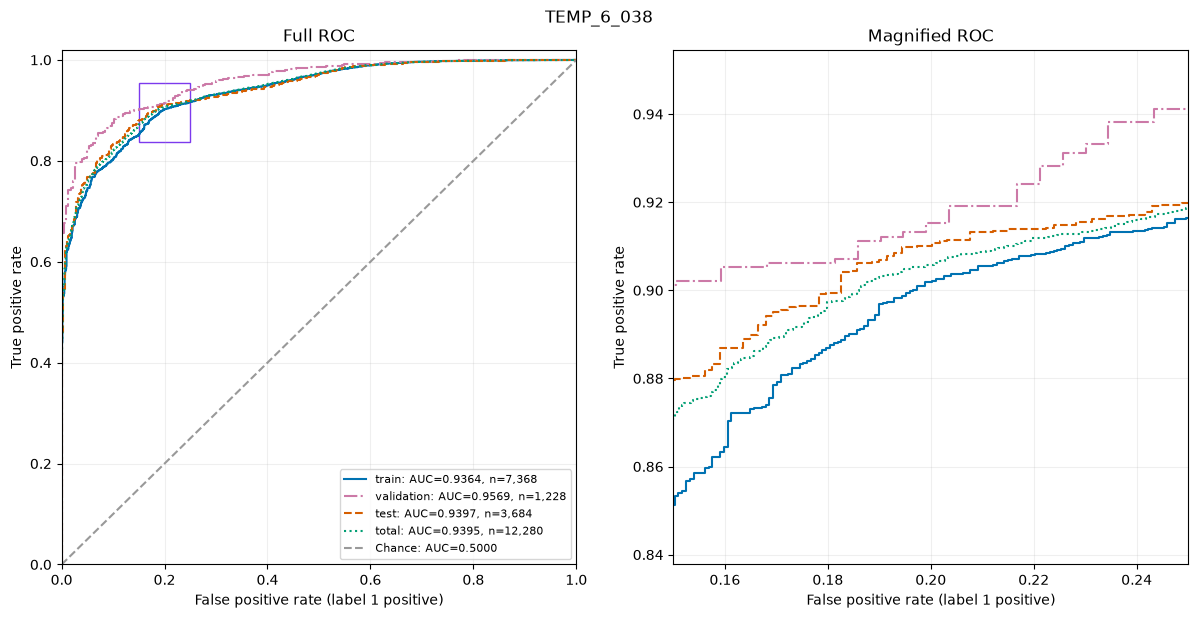

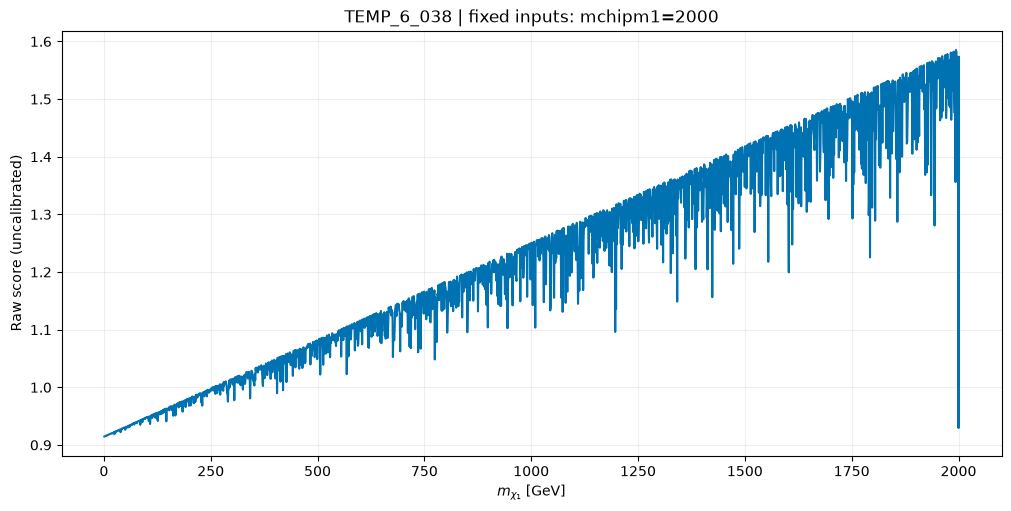

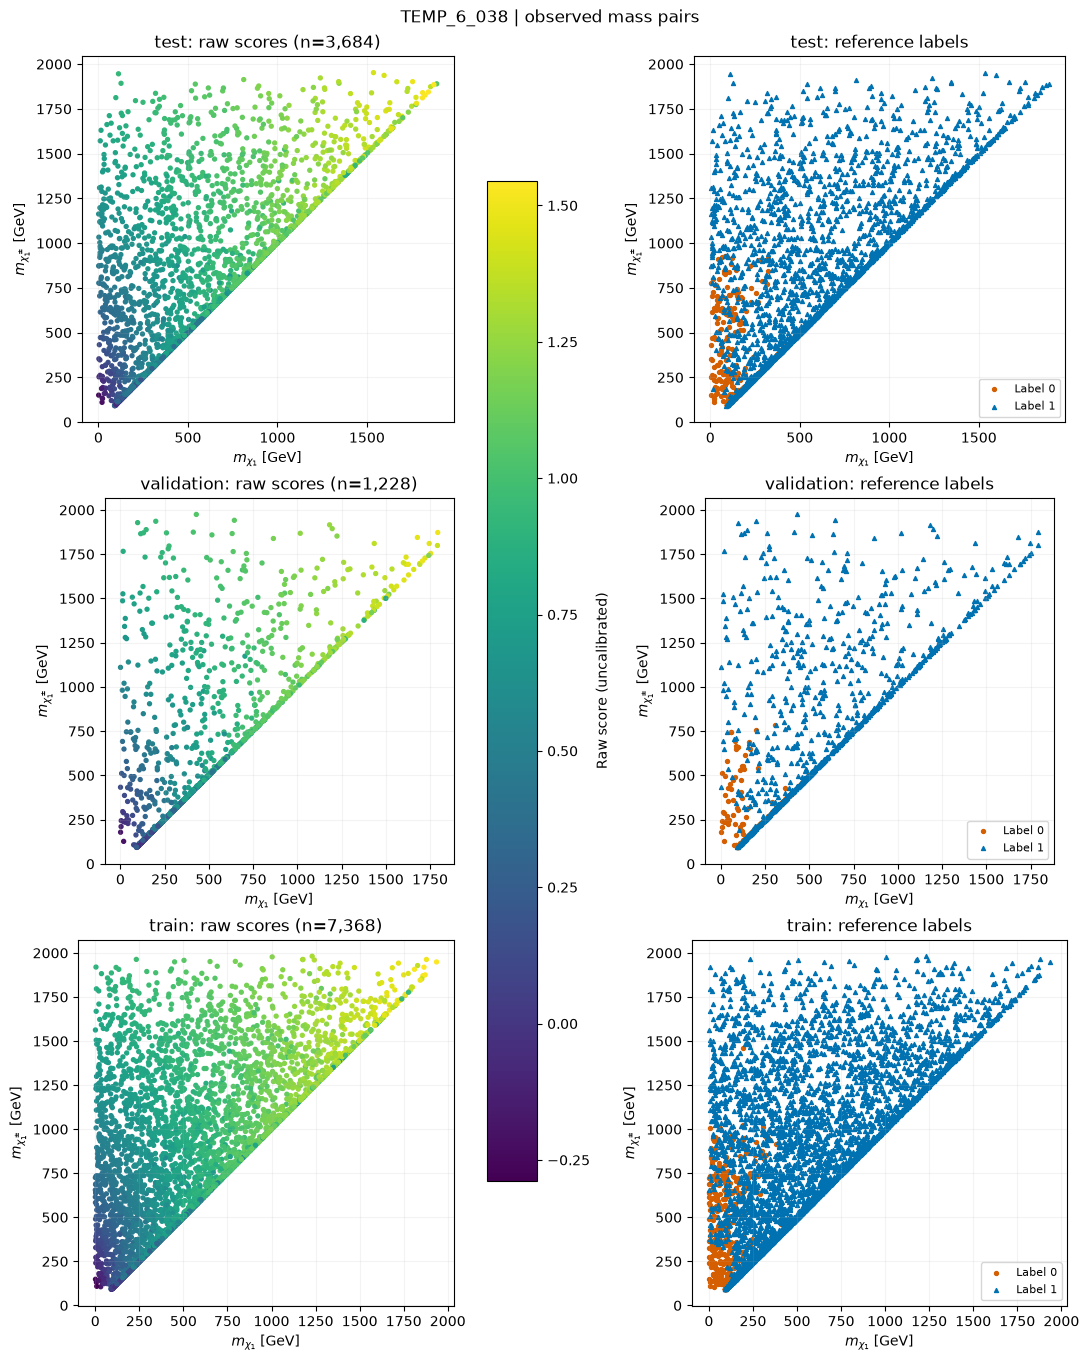

In [ ]:
# Version v5.3.1
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sr import (do_split, expr_indexer, auc_recorder, plot_roc_curve, plot_1d_mass,
                plot_mass_plane, plot_expr_folds_variability, save_plot)

PROJECT_DIR = Path.cwd().resolve()
RUN_DIR = PROJECT_DIR / "output/TEMP_6"                 # Change this at will
DATA_CSV = PROJECT_DIR / "data/masses_exclusions.csv"
EXPRESSION_ID = "TEMP_6_038"                            # Change this at will
FEATURES = ["mchi1", "mchipm1"]
SAVE_PLOTS, SHOW_PLOTS = False, True


HOF = pd.read_csv(RUN_DIR / "hall_of_fame.csv", float_precision="round_trip")
HOF_01 = expr_indexer(HOF, RUN_DIR.name, FEATURES)
selected = HOF_01.loc[HOF_01["Expression_ID"] == EXPRESSION_ID]
if selected.empty:
    raise ValueError(f"Expression_ID is absent from this run: {EXPRESSION_ID}")
df = pd.read_csv(DATA_CSV).dropna(subset=FEATURES + ["exclusion"])
X, y = df[FEATURES].astype(float), pd.to_numeric(df["exclusion"], errors="raise")
X_train, y_train, X_val, y_val, X_test, y_test, X_total, y_total = do_split(X, y)
datasets = {"train": (X_train, y_train), "validation": (X_val, y_val),
            "test": (X_test, y_test), "total": (X_total, y_total)}
HOF_02, evaluations = auc_recorder(selected, datasets)
equation = HOF_02.iloc[0]["Lambda_Equation"]
X_slice = pd.DataFrame({"mchi1": np.linspace(1, 2001, 2000), "mchipm1": 2000.0})
figures = {"roc_curve.pdf": plot_roc_curve(EXPRESSION_ID, evaluations, magnified=True),
           "mass_scan_1d.pdf": plot_1d_mass(equation, X_slice, Expression_ID=EXPRESSION_ID),
           "mass_plane.pdf": plot_mass_plane(EXPRESSION_ID, datasets, evaluations)}
# for filename, (fig, _) in figures.items():
#     if SAVE_PLOTS:
#         save_plot(fig, filename, RUN_DIR / "plots")
print(HOF_02[["Expression_ID", "train_auc", "val_auc", "test_auc", "total_auc"]].to_string(index=False))
if SHOW_PLOTS:
    plt.show()


        rows       auc
subset                
1        205  0.952569
2        205  0.974472
3        205  0.949890
4        205  0.936338
5        204  0.965528
6        204  0.956951
{'dataset': 'validation', 'rows': 1228, 'n_splits': 6, 'seed': 42, 'mean_subset_auc': 0.9559579276723936, 'sd_subset_auc': 0.01318039285910817, 'area_under_mean_roc': 0.9555479041916168}


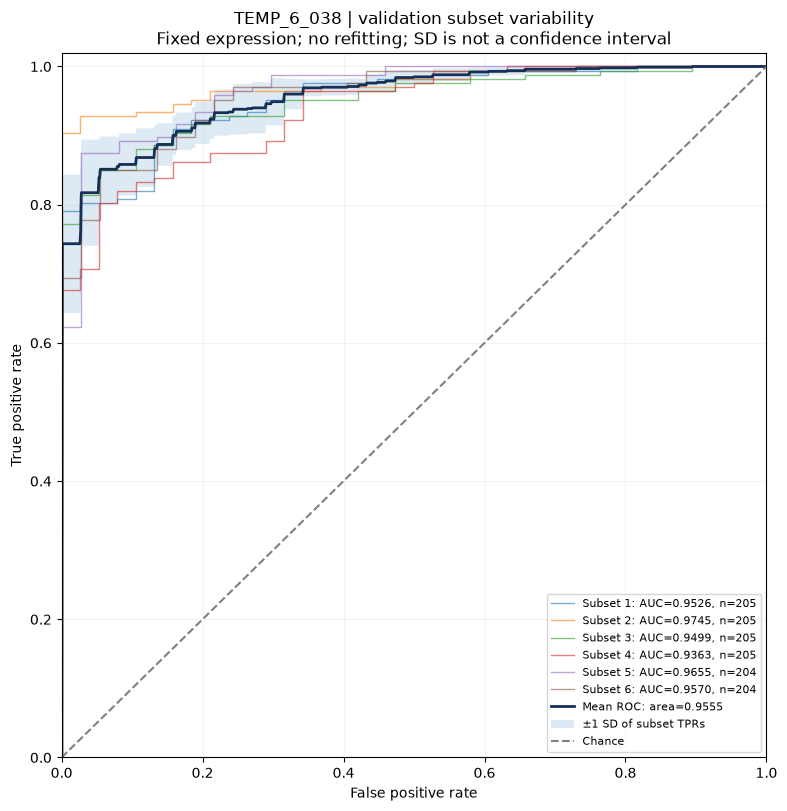

In [3]:
# Version v5.3.1
# Same fixed expression on stratified subsets; no fitting or refitting.
fold_fig, fold_ax, fold_table, summary, fold_positions = plot_expr_folds_variability(
    EXPRESSION_ID, datasets, evaluations)
print(fold_table.to_string(), summary, sep="\n")
if SAVE_PLOTS:
    save_plot(fold_fig, "subset_variability.pdf", RUN_DIR / "plots")
if SHOW_PLOTS:
    plt.show()
